# Experiment: Mental Health Burden and Forecasting Analysis

## Objective
Build one country-year analysis pipeline that answers the full track with the mental-health files in this project.

- Beginner: measure global prevalence and country-level change over time
- Intermediate: analyze gender disparities and model outcomes with the country-level structural variables available in-source
- Advanced: compare forecasting models, quantify burden with DALYs, and cluster countries by mental-health profile

## Important Note
The source files do not include GDP, income, schooling, or unemployment fields. For the intermediate model, I therefore use the structural variables that are available directly in the dataset bundle: `population`, `year`, `continent`, and gender-gap features.


In [1]:
from pathlib import Path

# Repo root is the parent of notebooks/, regardless of the notebook's cwd.
DATA_DIR = Path.cwd().resolve().parent / 'data'


In [2]:
# Configure the notebook environment and mute noisy warnings.
import os
import warnings

os.environ['LOKY_MAX_CPU_COUNT'] = '1'
warnings.filterwarnings('ignore')


In [3]:
# Import the core data libraries.
import numpy as np
import pandas as pd


In [4]:
# Import the visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
# Import notebook display helpers.
from IPython.display import display


In [6]:
# Import the machine-learning utilities used later.
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score


In [7]:
# Set notebook display options for wider summaries.
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')


In [8]:
# Set a consistent plotting theme for all charts.
sns.set_theme(style='whitegrid')


In [9]:
# Store the shared chart colors used throughout the notebook.
COLORS = {
    'blue': '#4C78A8',
    'orange': '#F58518',
    'green': '#54A24B',
    'red': '#E45756',
    'teal': '#72B7B2',
}


In [10]:
# Define the shared date range and a compatible RMSE helper.
START_YEAR = 1990
END_YEAR = 2019

def rmse(y_true, y_pred):
    return mean_squared_error(y_true, y_pred) ** 0.5


## Plan

1. Load the six mental-health source tables.
2. Keep only country-level rows in the shared `1990-2019` window.
3. Merge prevalence, disorder mix, DALY burden, population, and gender-gap features into one panel.
4. Answer the Beginner, Intermediate, and Advanced questions with tables, charts, and model comparisons.


In [11]:
# Load the raw source tables into memory.
raw_tables = {
    'mental_total': pd.read_csv(DATA_DIR / 'share-with-mental-and-substance-disorders.csv'),
    'depression_total': pd.read_csv(DATA_DIR / 'share-with-depression.csv'),
    'daly_share': pd.read_csv(DATA_DIR / 'mental-and-substance-use-as-share-of-disease.csv'),
    'disorder_breakdown': pd.read_csv(DATA_DIR / 'prevalence-by-mental-and-substance-use-disorder.csv'),
    'depression_by_sex': pd.read_csv(DATA_DIR / 'prevalence-of-depression-males-vs-females.csv'),
    'mental_by_sex': pd.read_csv(DATA_DIR / 'share-with-mental-or-substance-disorders-by-sex.csv'),
}


In [12]:
# Start the source summary with basic table sizes.
source_summary = pd.DataFrame({
    'table': list(raw_tables.keys()),
    'rows': [df.shape[0] for df in raw_tables.values()],
    'columns': [df.shape[1] for df in raw_tables.values()],
})


In [13]:
# Add the shared year coverage for each source table.
source_summary['year_min'] = [df['Year'].min() for df in raw_tables.values()]
source_summary['year_max'] = [df['Year'].max() for df in raw_tables.values()]


In [14]:
# Count how many distinct country or entity labels appear in each source.
source_summary['entities'] = [df['Entity'].nunique() for df in raw_tables.values()]


In [15]:
# Preview the source summary before cleaning.
display(source_summary)


,table,rows,columns,year_min,year_max,entities
0,mental_total,6780,4,1990,2019,226
1,depression_total,6780,4,1990,2019,226
2,daly_share,6840,4,1990,2019,228
3,disorder_breakdown,6840,10,1990,2019,228
4,depression_by_sex,56395,7,-10000,2021,316
5,mental_by_sex,56629,7,-10000,2021,326


In [16]:
# Create a helper that keeps only country rows in the shared year window.
def keep_countries(df):
    # Drop years outside the common project window.
    df = df[df['Year'].between(START_YEAR, END_YEAR)].copy()
    code = df['Code'].astype(str)
    # Remove aggregate OWID regions so comparisons stay country-level.
    return df[df['Code'].notna() & ~code.str.startswith('OWID_')].copy()


In [17]:
# Clean the total mental-disorder prevalence table.
mental = keep_countries(raw_tables['mental_total']).rename(columns={
    'Prevalence - Mental disorders - Sex: Both - Age: Age-standardized (Percent)': 'mental_prev'
})


In [18]:
# Clean the total depression prevalence table.
depression = keep_countries(raw_tables['depression_total']).rename(columns={
    'Prevalence - Depressive disorders - Sex: Both - Age: Age-standardized (Percent)': 'depression_prev'
})


In [19]:
# Clean the DALY burden table.
daly = keep_countries(raw_tables['daly_share']).rename(columns={
    'DALYs (Disability-Adjusted Life Years) - Mental disorders - Sex: Both - Age: All Ages (Percent)': 'daly_share'
})


In [20]:
# Define shorter names for the mood and psychosis prevalence columns.
disorder_rename_map = {
    'Prevalence - Schizophrenia - Sex: Both - Age: Age-standardized (Percent)': 'schizophrenia_prev',
    'Prevalence - Bipolar disorder - Sex: Both - Age: Age-standardized (Percent)': 'bipolar_prev',
    'Prevalence - Eating disorders - Sex: Both - Age: Age-standardized (Percent)': 'eating_prev',
    'Prevalence - Anxiety disorders - Sex: Both - Age: Age-standardized (Percent)': 'anxiety_prev',
}


In [21]:
# Add the remaining substance-use and depression column labels.
disorder_rename_map.update({
    'Prevalence - Drug use disorders - Sex: Both - Age: Age-standardized (Percent)': 'drug_prev',
    'Prevalence - Depressive disorders - Sex: Both - Age: Age-standardized (Percent)': 'depressive_prev',
    'Prevalence - Alcohol use disorders - Sex: Both - Age: Age-standardized (Percent)': 'alcohol_prev',
})


In [22]:
# Clean the disorder-level prevalence table.
disorders = keep_countries(raw_tables['disorder_breakdown']).rename(columns=disorder_rename_map)


In [23]:
# Clean the depression-by-sex table.
depression_by_sex = keep_countries(raw_tables['depression_by_sex']).rename(columns={
    'Prevalence - Depressive disorders - Sex: Male - Age: Age-standardized (Percent)': 'depression_male_prev',
    'Prevalence - Depressive disorders - Sex: Female - Age: Age-standardized (Percent)': 'depression_female_prev',
    'Population (historical estimates)': 'population',
    'Continent': 'continent',
})


In [24]:
# Clean the total mental-health-by-sex table.
mental_by_sex = keep_countries(raw_tables['mental_by_sex']).rename(columns={
    'Prevalence - Mental and substance use disorders - Sex: Male - Age: Age-standardized (Percent)': 'mental_male_prev',
    'Prevalence - Mental and substance use disorders - Sex: Female - Age: Age-standardized (Percent)': 'mental_female_prev',
    'Population (historical estimates)': 'population_from_total',
    'Continent': 'continent_from_total',
})


In [25]:
# Start the continent lookup with the depression-by-sex file.
continent_map = depression_by_sex[['Code', 'continent']]


In [26]:
# Use the total mental-health file as a fallback for missing labels.
continent_fallback = mental_by_sex[[
    'Code',
    'continent_from_total',
]].rename(columns={'continent_from_total': 'continent'})


In [27]:
# Combine both continent sources into one country lookup.
continent_map = pd.concat([continent_map, continent_fallback], ignore_index=True)
continent_map = continent_map.dropna().drop_duplicates(subset=['Code'])


In [28]:
# Check how many country codes have continent metadata.
print('Continent reference rows:', len(continent_map))


Continent reference rows: 250


In [29]:
# Start the core panel with total mental prevalence.
core_panel = mental[['Entity', 'Code', 'Year', 'mental_prev']].copy()


In [30]:
# Add overall depression prevalence into the core panel.
core_panel = core_panel.merge(
    depression[['Entity', 'Code', 'Year', 'depression_prev']],
    on=['Entity', 'Code', 'Year'],
    how='inner',
)


In [31]:
# Add DALY burden so the panel carries both prevalence and impact.
core_panel = core_panel.merge(
    daly[['Entity', 'Code', 'Year', 'daly_share']],
    on=['Entity', 'Code', 'Year'],
    how='inner',
)


In [32]:
# Group the core non-substance disorder columns.
primary_disorder_cols = ['schizophrenia_prev', 'bipolar_prev', 'eating_prev', 'anxiety_prev']


In [33]:
# Group the remaining disorder columns and combine them.
secondary_disorder_cols = ['drug_prev', 'depressive_prev', 'alcohol_prev']
disorder_cols = primary_disorder_cols + secondary_disorder_cols


In [34]:
# Add the disorder mix columns into the core panel.
core_panel = core_panel.merge(
    disorders[['Entity', 'Code', 'Year'] + disorder_cols],
    on=['Entity', 'Code', 'Year'],
    how='inner',
)


In [35]:
# Merge the depression-by-sex features into the panel.
mental_panel = core_panel.merge(
    depression_by_sex[[
        'Entity', 'Code', 'Year', 'depression_male_prev', 'depression_female_prev', 'population'
    ]],
    on=['Entity', 'Code', 'Year'],
    how='left',
)


In [36]:
# Merge the total mental-health-by-sex features into the panel.
mental_panel = mental_panel.merge(
    mental_by_sex[['Entity', 'Code', 'Year', 'mental_male_prev', 'mental_female_prev']],
    on=['Entity', 'Code', 'Year'],
    how='left',
)


In [37]:
# Attach the continent lookup to the final panel.
mental_panel = mental_panel.merge(continent_map, on='Code', how='left')


In [38]:
# Create the gender-gap features used later in the analysis.
mental_panel['depression_gender_gap'] = mental_panel['depression_female_prev'] - mental_panel['depression_male_prev']
mental_panel['mental_gender_gap'] = mental_panel['mental_female_prev'] - mental_panel['mental_male_prev']


In [39]:
# Create the population-scale feature used for modeling.
mental_panel['log_population'] = np.log10(mental_panel['population'])


In [40]:
# Express depression and anxiety as shares of total mental prevalence.
mental_panel['depression_share_of_total'] = mental_panel['depression_prev'] / mental_panel['mental_prev']
mental_panel['anxiety_share'] = mental_panel['anxiety_prev'] / mental_panel['mental_prev']


In [41]:
# Group the substance-use and severe-disorder shares into separate ratios.
mental_panel['substance_share'] = (mental_panel['drug_prev'] + mental_panel['alcohol_prev']) / mental_panel['mental_prev']
mental_panel['severe_share'] = (mental_panel['schizophrenia_prev'] + mental_panel['bipolar_prev']) / mental_panel['mental_prev']


In [42]:
# Compare disease burden against prevalence with a DALY-to-prevalence ratio.
mental_panel['burden_ratio'] = mental_panel['daly_share'] / mental_panel['mental_prev']


In [43]:
# Summarize any missing values after the merge.
missing_summary = mental_panel.isna().sum().rename('missing_values')
display(missing_summary[missing_summary > 0].to_frame())


,missing_values
mental_male_prev,656
mental_female_prev,656
mental_gender_gap,656


In [44]:
# Print the final panel shape and time window.
print('Country-year rows:', mental_panel.shape[0])
print('Countries:', mental_panel['Code'].nunique())
print('Year window:', mental_panel['Year'].min(), 'to', mental_panel['Year'].max())


Country-year rows: 6060
Countries: 202
Year window: 1990 to 2019


In [45]:
# Preview the cleaned country-year panel.
display(
    mental_panel[[
        'Entity', 'Code', 'Year', 'continent', 'population', 'mental_prev', 'depression_prev',
        'daly_share', 'depression_gender_gap', 'mental_gender_gap'
    ]].head()
)


,Entity,Code,Year,continent,population,mental_prev,depression_prev,daly_share,depression_gender_gap,mental_gender_gap
0,Afghanistan,AFG,1990,Asia,"12,412,311.0000",16.6592,5.1253,1.6967,1.5686,0.1855
1,Afghanistan,AFG,1991,Asia,"13,299,016.0000",16.7651,5.1163,1.7343,1.5598,0.1019
2,Afghanistan,AFG,1992,Asia,"14,485,543.0000",16.8745,5.1066,1.7912,1.5518,0.0407
3,Afghanistan,AFG,1993,Asia,"15,816,601.0000",16.9907,5.1003,1.7768,1.5419,-0.0107
4,Afghanistan,AFG,1994,Asia,"17,075,728.0000",17.1127,5.0994,1.7130,1.5376,-0.0441


## Beginner Analysis

Goal:

- Measure how mental-disorder prevalence behaves globally over time.
- Identify which countries changed the most from `1990` to `2019`.
- Visualize country-level trajectories for the biggest movers.


In [46]:
# Compute the yearly global country mean for mental prevalence.
global_mean_mental = mental_panel.groupby('Year')['mental_prev'].mean()


In [47]:
# Compute the yearly population-weighted mental prevalence.
global_weighted_mental = mental_panel.groupby('Year').apply(
    lambda g: np.average(g['mental_prev'], weights=g['population'])
)


In [48]:
# Compute the yearly global country mean for depression prevalence.
global_mean_depression = mental_panel.groupby('Year')['depression_prev'].mean()


In [49]:
# Assemble the yearly global trend table.
global_trend = pd.DataFrame({
    'country_mean_mental_prev': global_mean_mental,
    'population_weighted_mental_prev': global_weighted_mental,
    'country_mean_depression_prev': global_mean_depression,
}).reset_index()


In [50]:
# Preview the top and bottom of the yearly trend table.
display(global_trend.head())
display(global_trend.tail())


,Year,country_mean_mental_prev,population_weighted_mental_prev,country_mean_depression_prev
0,1990,13.3237,13.1401,3.9832
1,1991,13.3275,13.1921,3.9812
2,1992,13.3317,13.2384,3.9798
3,1993,13.3356,13.2766,3.9788
4,1994,13.3391,13.3032,3.9785


,Year,country_mean_mental_prev,population_weighted_mental_prev,country_mean_depression_prev
25,2015,13.2848,13.0774,3.9040
26,2016,13.2827,13.0802,3.9041
27,2017,13.2810,13.0843,3.9051
28,2018,13.2824,13.0761,3.9099
29,2019,13.2869,13.0610,3.9185


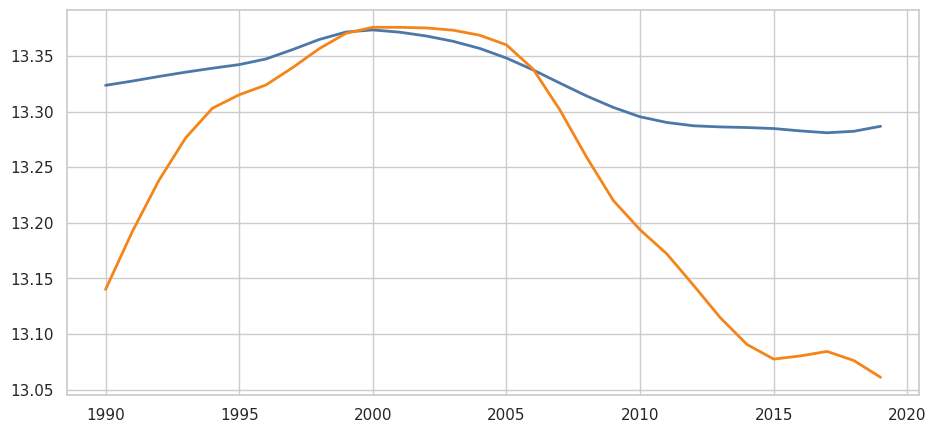

In [51]:
# Start the global trend chart and draw the two prevalence lines.
plt.figure(figsize=(11, 5))
plt.plot(global_trend['Year'], global_trend['country_mean_mental_prev'], label='Country mean', color=COLORS['blue'], linewidth=2)
plt.plot(global_trend['Year'], global_trend['population_weighted_mental_prev'], label='Population weighted', color=COLORS['orange'], linewidth=2)


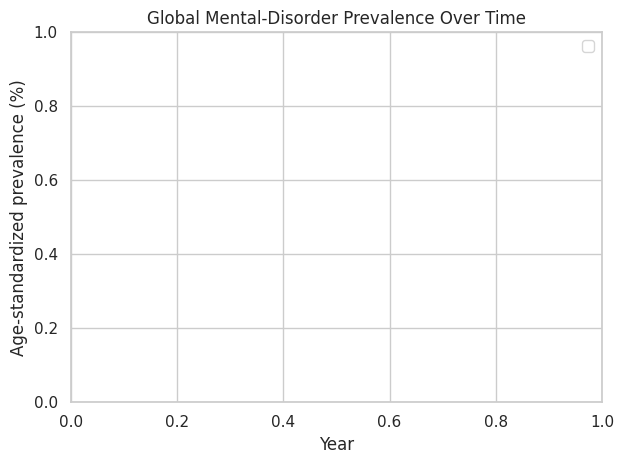

In [52]:
# Label and render the global trend chart.
plt.title('Global Mental-Disorder Prevalence Over Time')
plt.xlabel('Year')
plt.ylabel('Age-standardized prevalence (%)')
plt.legend()
plt.tight_layout()
plt.show()


In [53]:
# Pivot the panel so 1990 and 2019 sit side by side.
country_change = (
    mental_panel[mental_panel['Year'].isin([START_YEAR, END_YEAR])]
    .pivot_table(index=['Entity', 'Code'], columns='Year', values='mental_prev')
    .dropna()
    .reset_index()
    .rename(columns={START_YEAR: 'mental_prev_1990', END_YEAR: 'mental_prev_2019'})
)


In [54]:
# Calculate the absolute and percentage change by country.
country_change['abs_change'] = country_change['mental_prev_2019'] - country_change['mental_prev_1990']
country_change['pct_change'] = 100 * country_change['abs_change'] / country_change['mental_prev_1990']


In [55]:
# Select the biggest increases and declines.
top_increase = country_change.sort_values('abs_change', ascending=False).head(10)
top_decline = country_change.sort_values('abs_change', ascending=True).head(10)


In [56]:
# Display the countries with the biggest prevalence changes.
display(top_increase)
display(top_decline)


Year,Entity,Code,mental_prev_1990,mental_prev_2019,abs_change,pct_change
192,United States,USA,15.5565,16.9346,1.3781,8.8590
113,Mexico,MEX,10.9638,12.2617,1.2979,11.8383
25,Brazil,BRA,15.4899,16.7171,1.2271,7.9221
126,New Zealand,NZL,18.0475,19.0366,0.9892,5.4809
168,Spain,ESP,17.4253,18.3197,0.8944,5.1328
101,Libya,LBY,14.6412,15.3991,0.7580,5.1769
9,Australia,AUS,18.6928,19.3479,0.6552,3.5049
136,Pakistan,PAK,12.4734,13.0833,0.6098,4.8892
67,Germany,DEU,14.3957,15.0008,0.6051,4.2035
165,Somalia,SOM,13.8179,14.3628,0.5449,3.9436


Year,Entity,Code,mental_prev_1990,mental_prev_2019,abs_change,pct_change
14,Bangladesh,BGD,13.5022,11.8013,-1.7009,-12.5974
121,Myanmar,MMR,12.2441,10.8869,-1.3572,-11.0843
62,Finland,FIN,16.2765,14.9640,-1.3125,-8.0639
30,Cambodia,KHM,13.4824,12.3609,-1.1215,-8.3185
23,Bosnia and Herzegovina,BIH,12.5323,11.5134,-1.0189,-8.1302
58,Estonia,EST,13.1943,12.1946,-0.9997,-7.5766
21,Bhutan,BTN,13.0203,12.0694,-0.9510,-7.3038
60,Ethiopia,ETH,13.4170,12.4784,-0.9386,-6.9957
107,Maldives,MDV,12.0001,11.0730,-0.9271,-7.7259
96,Laos,LAO,12.9284,12.0397,-0.8888,-6.8744


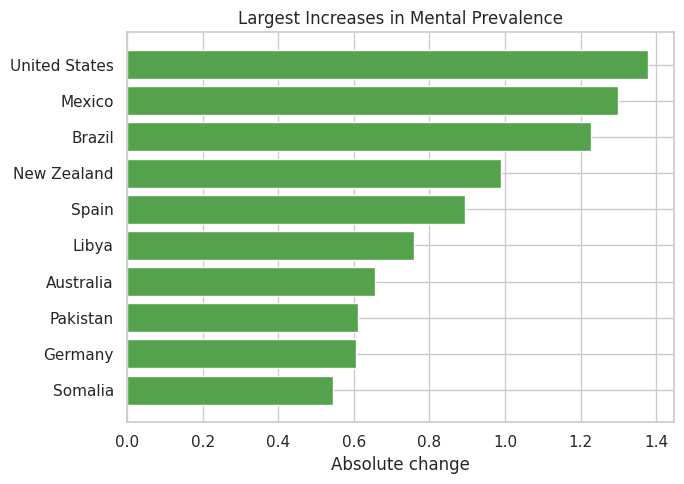

In [57]:
# Plot the countries with the largest increases.
plt.figure(figsize=(7, 5))
plt.barh(top_increase.sort_values('abs_change')['Entity'], top_increase.sort_values('abs_change')['abs_change'], color=COLORS['green'])
plt.title('Largest Increases in Mental Prevalence')
plt.xlabel('Absolute change')
plt.tight_layout()
plt.show()


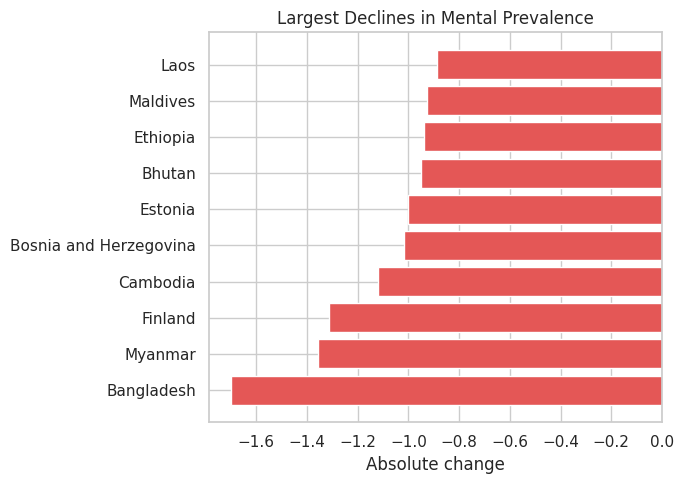

In [58]:
# Plot the countries with the largest declines.
plt.figure(figsize=(7, 5))
plt.barh(top_decline.sort_values('abs_change')['Entity'], top_decline.sort_values('abs_change')['abs_change'], color=COLORS['red'])
plt.title('Largest Declines in Mental Prevalence')
plt.xlabel('Absolute change')
plt.tight_layout()
plt.show()


In [59]:
# Collect the biggest movers for a trajectory comparison.
selected_codes = pd.concat([
    top_increase[['Entity', 'Code']].head(5),
    top_decline[['Entity', 'Code']].head(5),
]).drop_duplicates()
selected_trend = mental_panel.merge(selected_codes, on=['Entity', 'Code'], how='inner')


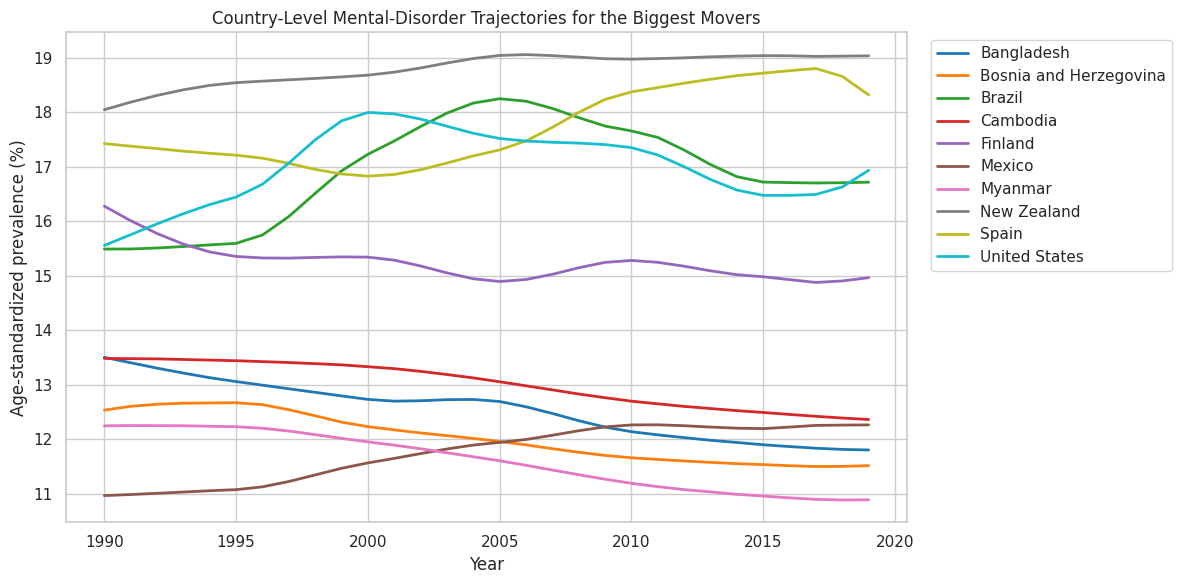

In [60]:
# Plot the long-run trajectories for the biggest movers.
plt.figure(figsize=(12, 6))
sns.lineplot(data=selected_trend, x='Year', y='mental_prev', hue='Entity', linewidth=2, palette='tab10')
plt.title('Country-Level Mental-Disorder Trajectories for the Biggest Movers')
plt.xlabel('Year')
plt.ylabel('Age-standardized prevalence (%)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## Intermediate Analysis

Goal:

- Compare female and male depression prevalence over time.
- Identify the countries and continents with the widest gender gaps.
- Model mental-health outcomes with the structural variables available in-source.


In [61]:
# Build a compact summary of gender-gap statistics.
gender_summary = pd.DataFrame([
    {'metric': 'Average depression prevalence gap (female - male)', 'value': mental_panel['depression_gender_gap'].mean()},
    {'metric': 'Average total mental prevalence gap (female - male)', 'value': mental_panel['mental_gender_gap'].mean()},
    {'metric': 'Maximum depression prevalence gap observed', 'value': mental_panel['depression_gender_gap'].max()},
    {'metric': 'Minimum depression prevalence gap observed', 'value': mental_panel['depression_gender_gap'].min()},
])


In [62]:
# Aggregate the depression gender gap by year.
gender_trend = mental_panel.groupby('Year').agg(
    depression_male_prev=('depression_male_prev', 'mean'),
    depression_female_prev=('depression_female_prev', 'mean'),
    depression_gender_gap=('depression_gender_gap', 'mean'),
).reset_index()


In [63]:
# Display the gender summary and trend tables.
display(gender_summary)
display(gender_trend.head())


,metric,value
0,Average depression prevalence gap (female - male),1.5588
1,Average total mental prevalence gap (female - ...,0.7062
2,Maximum depression prevalence gap observed,5.4883
3,Minimum depression prevalence gap observed,0.1018


,Year,depression_male_prev,depression_female_prev,depression_gender_gap
0,1990,3.1530,4.7750,1.6220
1,1991,3.1527,4.7716,1.6189
2,1992,3.1527,4.7687,1.6160
3,1993,3.1530,4.7663,1.6133
4,1994,3.1537,4.7646,1.6109


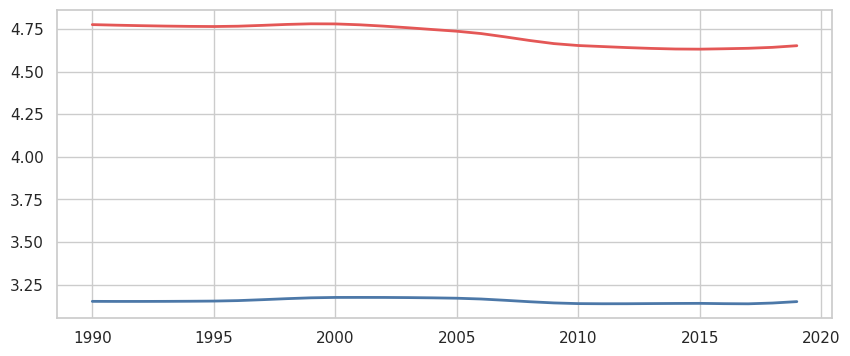

In [64]:
# Start the gender trend chart and draw the male and female series.
plt.figure(figsize=(10, 4))
plt.plot(gender_trend['Year'], gender_trend['depression_male_prev'], label='Male', color=COLORS['blue'], linewidth=2)
plt.plot(gender_trend['Year'], gender_trend['depression_female_prev'], label='Female', color=COLORS['red'], linewidth=2)


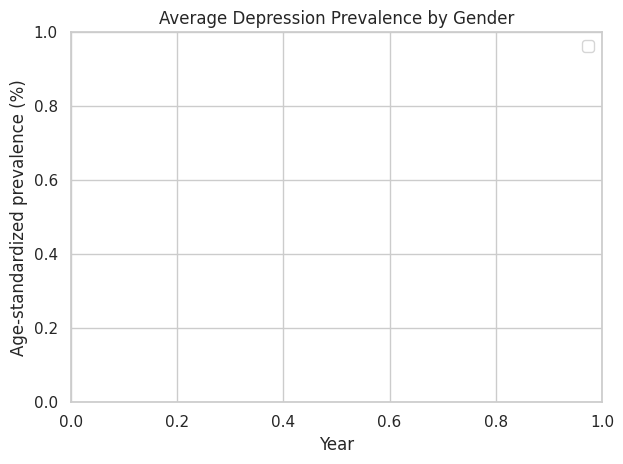

In [65]:
# Label and render the gender trend chart.
plt.title('Average Depression Prevalence by Gender')
plt.xlabel('Year')
plt.ylabel('Age-standardized prevalence (%)')
plt.legend()
plt.tight_layout()
plt.show()


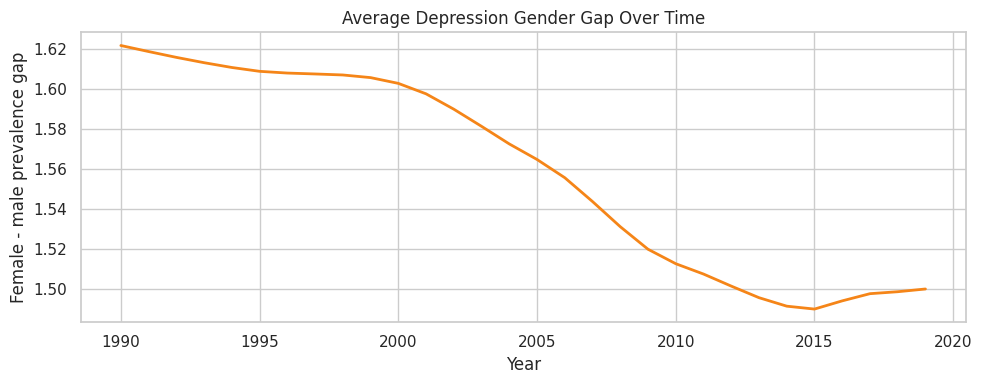

In [66]:
# Plot the average depression gender gap over time.
plt.figure(figsize=(10, 4))
plt.plot(gender_trend['Year'], gender_trend['depression_gender_gap'], color=COLORS['orange'], linewidth=2)
plt.title('Average Depression Gender Gap Over Time')
plt.xlabel('Year')
plt.ylabel('Female - male prevalence gap')
plt.tight_layout()
plt.show()


In [67]:
# Rank countries by the size of the 2019 depression gender gap.
gap_2019 = mental_panel[mental_panel['Year'] == END_YEAR].sort_values('depression_gender_gap', ascending=False)[[
    'Entity', 'continent', 'depression_male_prev', 'depression_female_prev', 'depression_gender_gap'
]]


In [68]:
# Summarize 2019 gender gaps and burden at the continent level.
continent_2019 = mental_panel[mental_panel['Year'] == END_YEAR].groupby('continent').agg(
    countries=('Code', 'nunique'),
    avg_mental_prev=('mental_prev', 'mean'),
    avg_depression_gap=('depression_gender_gap', 'mean'),
    avg_daly_share=('daly_share', 'mean'),
).sort_values('avg_depression_gap', ascending=False)


In [69]:
# Display the 2019 country and continent rankings.
display(gap_2019.head(15))
display(continent_2019)


,Entity,continent,depression_male_prev,depression_female_prev,depression_gender_gap
1979,Gambia,Africa,3.2641,7.8953,4.6312
3029,Liberia,Africa,2.8654,6.3993,3.5339
5069,Spain,Europe,3.5598,6.7367,3.1770
4259,Paraguay,South America,2.4286,5.3333,2.9047
2129,Greenland,North America,4.9800,7.8243,2.8444
5189,Sweden,Europe,3.1236,5.7980,2.6744
4379,Portugal,Europe,3.4271,6.0295,2.6024
2519,Iran,Asia,3.8494,6.3395,2.4902
2729,Jordan,Asia,3.2390,5.7206,2.4815
1109,Chile,South America,2.6882,5.1244,2.4361


,countries,avg_mental_prev,avg_depression_gap,avg_daly_share
continent,,,,
South America,12,14.6562,1.6643,6.7032
Africa,54,12.6619,1.6542,3.8660
North America,27,14.3083,1.6394,6.0682
Europe,43,13.9737,1.6158,6.2501
Asia,46,12.7621,1.3296,6.3884
Oceania,20,12.5039,0.9378,4.3685


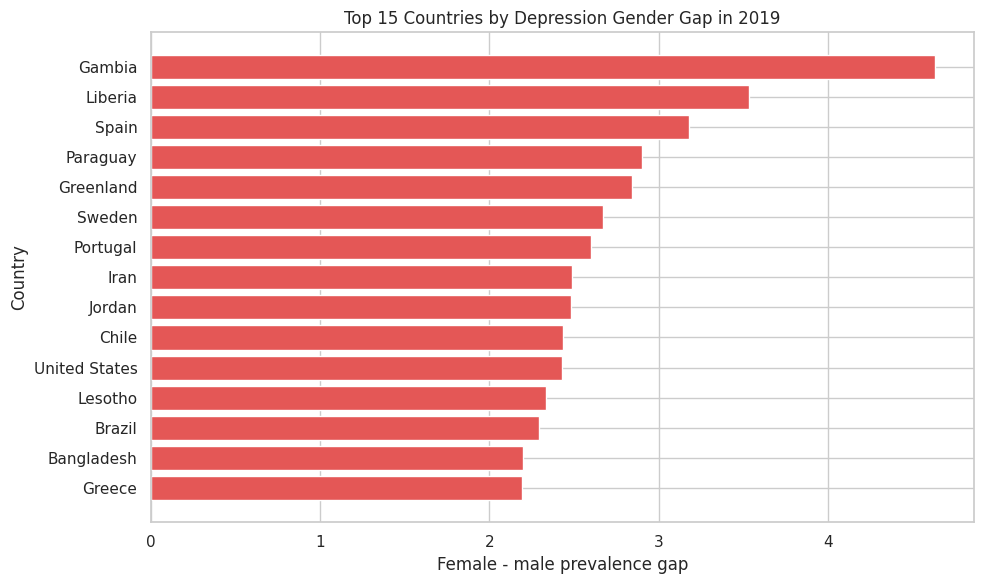

In [70]:
# Plot the top 15 depression gender gaps in 2019.
top_gap_plot = gap_2019.head(15).sort_values('depression_gender_gap')
plt.figure(figsize=(10, 6))
plt.barh(top_gap_plot['Entity'], top_gap_plot['depression_gender_gap'], color=COLORS['red'])
plt.title('Top 15 Countries by Depression Gender Gap in 2019')
plt.xlabel('Female - male prevalence gap')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


### Structural-Proxy Model

The source data does not include classic socioeconomic indicators such as GDP or income. To stay honest about the data we actually have, this model predicts `mental_prev` from:

- `Year`
- `log_population`
- `depression_gender_gap`
- `continent`

This turns the intermediate modeling section into a structural-proxy benchmark rather than a full socioeconomic model.


In [71]:
# Keep only the rows needed for the structural-proxy model.
model_df = mental_panel.dropna(subset=['mental_prev', 'log_population', 'depression_gender_gap', 'continent']).copy()
feature_cols = ['Year', 'log_population', 'depression_gender_gap', 'continent']
target_col = 'mental_prev'


In [72]:
# Split the structural-proxy model into train and test periods.
train = model_df[model_df['Year'] <= 2014].copy()
test = model_df[model_df['Year'] >= 2015].copy()


In [73]:
# List the numeric and categorical model inputs.
numeric_features = ['Year', 'log_population', 'depression_gender_gap']
categorical_features = ['continent']


In [74]:
# Define the numeric preprocessing steps for the structural model.
model_num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])


In [75]:
# Define the categorical preprocessing steps for the structural model.
model_cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])


In [76]:
# Combine the numeric and categorical preprocessing branches.
preprocessor = ColumnTransformer([
    ('num', model_num_pipe, numeric_features),
    ('cat', model_cat_pipe, categorical_features),
])


In [77]:
# Define the models to compare in the structural-proxy benchmark.
models = {
    'RandomForest': RandomForestRegressor(n_estimators=250, random_state=42, min_samples_leaf=3, n_jobs=1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42, max_depth=5),
}


In [78]:
# Prepare containers for the model results and fitted pipelines.
model_results = []
fitted_models = {}


In [79]:
# Define a helper that trains and scores one structural model.
def evaluate_structural_model(name, model):
    pipe = Pipeline([('prep', preprocessor), ('model', model)])
    pipe.fit(train[feature_cols], train[target_col])
    pred = pipe.predict(test[feature_cols])
    metrics = {'Model': name, 'RMSE': rmse(test[target_col], pred), 'MAE': mean_absolute_error(test[target_col], pred), 'R2': r2_score(test[target_col], pred)}
    return pipe, metrics


In [80]:
# Train each structural model with the shared helper.
for name, model in models.items():
    pipe, metrics = evaluate_structural_model(name, model)
    fitted_models[name] = pipe
    model_results.append(metrics)


In [81]:
# Pick the best structural-proxy model by RMSE.
model_results_df = pd.DataFrame(model_results).sort_values('RMSE').reset_index(drop=True)
best_model_name = model_results_df.loc[0, 'Model']
best_model = fitted_models[best_model_name]
best_pred = best_model.predict(test[feature_cols])


In [82]:
# Display the structural-proxy model comparison.
display(model_results_df)
print('Best structural-proxy model:', best_model_name)


,Model,RMSE,MAE,R2
0,RandomForest,1.0289,0.6033,0.7442
1,HistGradientBoosting,1.1513,0.8018,0.6797


Best structural-proxy model: RandomForest


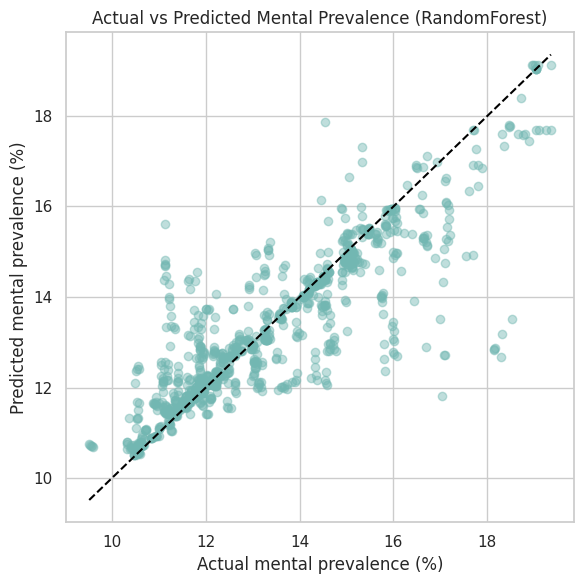

In [83]:
# Plot actual versus predicted values for the best structural model.
plt.figure(figsize=(6, 6))
plt.scatter(test[target_col], best_pred, alpha=0.45, color=COLORS['teal'])
plt.plot([test[target_col].min(), test[target_col].max()], [test[target_col].min(), test[target_col].max()], linestyle='--', color='black')
plt.title(f'Actual vs Predicted Mental Prevalence ({best_model_name})')
plt.xlabel('Actual mental prevalence (%)')
plt.ylabel('Predicted mental prevalence (%)')
plt.tight_layout()
plt.show()


## Advanced Analysis

Goal:

- Build and compare forecasting models for mental-prevalence prediction.
- Quantify burden by relating disorder prevalence to DALY share.
- Group countries into interpretable mental-health clusters.


In [84]:
# Sort the panel before building lagged forecasting features.
forecast_panel = mental_panel.sort_values(['Code', 'Year']).copy()


In [85]:
# List the source columns that will receive one-year lag features.
lag_source_cols = [
    'mental_prev', 'depression_prev', 'daly_share', 'depression_gender_gap',
    'mental_gender_gap', 'log_population', 'anxiety_prev', 'alcohol_prev',
    'drug_prev', 'eating_prev', 'schizophrenia_prev', 'bipolar_prev'
]


In [86]:
# Create one-year lag features for each forecasting input.
for col in lag_source_cols:
    # Each lag uses only information that would have been known last year.
    forecast_panel[f'{col}_lag1'] = forecast_panel.groupby('Code')[col].shift(1)


In [87]:
# Capture a longer memory of total mental prevalence.
forecast_panel['mental_prev_lag3'] = forecast_panel.groupby('Code')['mental_prev'].shift(3)


In [88]:
# Smooth recent prevalence and DALY burden with rolling three-year averages.
forecast_panel['mental_prev_roll3'] = forecast_panel.groupby('Code')['mental_prev'].transform(
    lambda s: s.shift(1).rolling(3).mean()
)
forecast_panel['daly_roll3'] = forecast_panel.groupby('Code')['daly_share'].transform(
    lambda s: s.shift(1).rolling(3).mean()
)


In [89]:
# Drop rows that are still missing required forecast inputs.
forecast_ready = forecast_panel.dropna(subset=[
    'mental_prev_lag1', 'mental_prev_lag3', 'mental_prev_roll3', 'daly_share_lag1', 'daly_roll3', 'continent'
]).copy()


In [90]:
# List the features used in the forecasting comparison.
forecast_features = [
    'Year', 'continent', 'log_population_lag1', 'mental_prev_lag1', 'mental_prev_lag3',
    'mental_prev_roll3', 'depression_prev_lag1', 'daly_share_lag1', 'daly_roll3',
    'depression_gender_gap_lag1', 'mental_gender_gap_lag1', 'anxiety_prev_lag1',
    'alcohol_prev_lag1', 'drug_prev_lag1', 'eating_prev_lag1', 'schizophrenia_prev_lag1', 'bipolar_prev_lag1'
]


In [91]:
# Split the forecasting dataset into train and test periods.
forecast_train = forecast_ready[forecast_ready['Year'] <= 2014].copy()
forecast_test = forecast_ready[forecast_ready['Year'] >= 2015].copy()


In [92]:
# Separate the forecast features into numeric and categorical groups.
forecast_numeric = [col for col in forecast_features if col != 'continent']
forecast_categorical = ['continent']


In [93]:
# Define the numeric preprocessing steps for the forecasting models.
forecast_num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])


In [94]:
# Define the categorical preprocessing steps for the forecasting models.
forecast_cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])


In [95]:
# Combine the forecasting preprocessing branches.
forecast_preprocessor = ColumnTransformer([
    ('num', forecast_num_pipe, forecast_numeric),
    ('cat', forecast_cat_pipe, forecast_categorical),
])


In [96]:
# Define the models compared in the forecasting section.
forecast_models = {
    'Persistence': None,
    'RandomForest': RandomForestRegressor(n_estimators=300, random_state=42, min_samples_leaf=2, n_jobs=1),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=42, max_depth=6),
}


In [97]:
# Initialize the container for the forecast-model metrics.
forecast_results = []


In [98]:
# Score the persistence baseline using last year's mental prevalence.
persistence_pred = forecast_test['mental_prev_lag1']
forecast_results.append({
    'Model': 'Persistence',
    'RMSE': rmse(forecast_test['mental_prev'], persistence_pred),
    'MAE': mean_absolute_error(forecast_test['mental_prev'], persistence_pred),
    'R2': r2_score(forecast_test['mental_prev'], persistence_pred),
})


In [99]:
# Define a helper that trains and scores one learned forecast model.
def evaluate_forecast_model(name, model):
    pipe = Pipeline([('prep', forecast_preprocessor), ('model', model)])
    pipe.fit(forecast_train[forecast_features], forecast_train['mental_prev'])
    pred = pipe.predict(forecast_test[forecast_features])
    metrics = {'Model': name, 'RMSE': rmse(forecast_test['mental_prev'], pred), 'MAE': mean_absolute_error(forecast_test['mental_prev'], pred), 'R2': r2_score(forecast_test['mental_prev'], pred)}
    return metrics


In [100]:
# Train the learned forecasting models.
for name, model in forecast_models.items():
    if model is None:
        continue
    forecast_results.append(evaluate_forecast_model(name, model))


In [101]:
# Display the forecast-model comparison.
forecast_results_df = pd.DataFrame(forecast_results).sort_values('RMSE').reset_index(drop=True)
display(forecast_results_df)


,Model,RMSE,MAE,R2
0,Persistence,0.0419,0.0221,0.9996
1,RandomForest,0.0434,0.0237,0.9995
2,HistGradientBoosting,0.0570,0.0313,0.9992


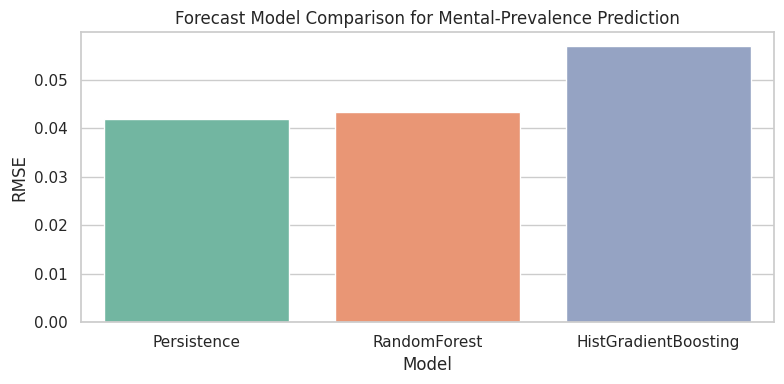

In [102]:
# Plot the forecast-model comparison.
plt.figure(figsize=(8, 4))
sns.barplot(data=forecast_results_df, x='Model', y='RMSE', palette='Set2')
plt.title('Forecast Model Comparison for Mental-Prevalence Prediction')
plt.ylabel('RMSE')
plt.xlabel('Model')
plt.tight_layout()
plt.show()


In [103]:
# List the features compared against DALY share.
impact_features = [
    'mental_prev', 'depression_prev', 'anxiety_prev', 'alcohol_prev', 'drug_prev',
    'eating_prev', 'schizophrenia_prev', 'bipolar_prev', 'depression_gender_gap', 'mental_gender_gap'
]


In [104]:
# Compute the correlation of each disorder metric with DALY share.
impact_corr = mental_panel[impact_features + ['daly_share']].corr(numeric_only=True)['daly_share']
impact_corr = impact_corr.sort_values(ascending=False).reset_index()
impact_corr = impact_corr.rename(columns={'index': 'feature', 'daly_share': 'correlation_with_daly'})


In [105]:
# Rank the highest DALY-burden countries in 2019.
burden_2019 = mental_panel[mental_panel['Year'] == END_YEAR].sort_values('burden_ratio', ascending=False)[[
    'Entity', 'continent', 'mental_prev', 'daly_share', 'burden_ratio'
]].head(15)


In [106]:
# Display the burden-correlation and burden-ranking tables.
display(impact_corr)
display(burden_2019)


,feature,correlation_with_daly
0,daly_share,1.0000
1,eating_prev,0.7139
2,anxiety_prev,0.6455
3,schizophrenia_prev,0.6326
4,bipolar_prev,0.6190
5,mental_prev,0.5734
6,mental_gender_gap,0.5141
7,drug_prev,0.4589
8,alcohol_prev,0.1681
9,depression_gender_gap,0.1091


,Entity,continent,mental_prev,daly_share,burden_ratio
4439,Qatar,Asia,13.6277,13.6702,1.0031
2849,Kuwait,Asia,14.0464,12.2259,0.8704
419,Bahrain,Asia,14.5707,11.4878,0.7884
4079,Oman,Asia,13.7301,10.4120,0.7583
3239,Maldives,Asia,11.0730,8.0588,0.7278
5729,United Arab Emirates,Asia,12.5313,9.0044,0.7186
2729,Jordan,Asia,15.0417,10.2431,0.6810
2609,Israel,Asia,14.4834,9.6270,0.6647
4739,Saudi Arabia,Asia,13.6971,8.9208,0.6513
4169,Palestine,Asia,18.1397,11.0582,0.6096


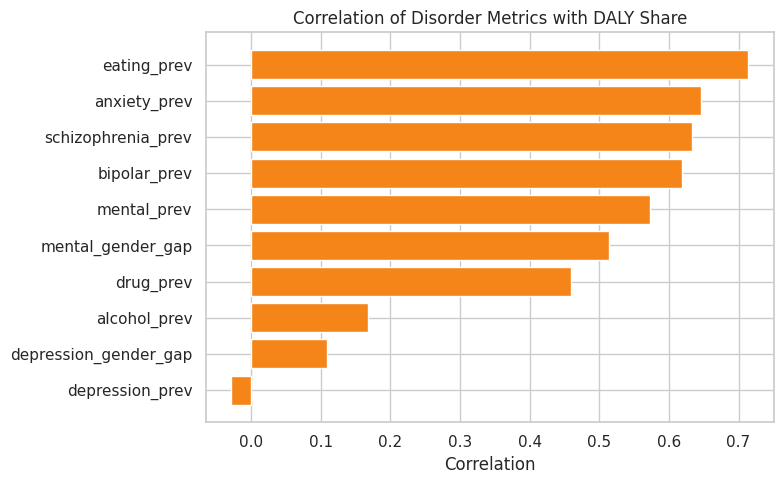

In [107]:
# Plot the DALY correlations for the disorder metrics.
corr_plot = impact_corr[impact_corr['feature'] != 'daly_share'].sort_values('correlation_with_daly')
plt.figure(figsize=(8, 5))
plt.barh(corr_plot['feature'], corr_plot['correlation_with_daly'], color=COLORS['orange'])
plt.title('Correlation of Disorder Metrics with DALY Share')
plt.xlabel('Correlation')
plt.tight_layout()
plt.show()


In [108]:
# Keep only the 2019 observations for the burden scatter chart.
scatter_df = mental_panel[mental_panel['Year'] == END_YEAR].copy()


<Axes: xlabel='mental_prev', ylabel='daly_share'>

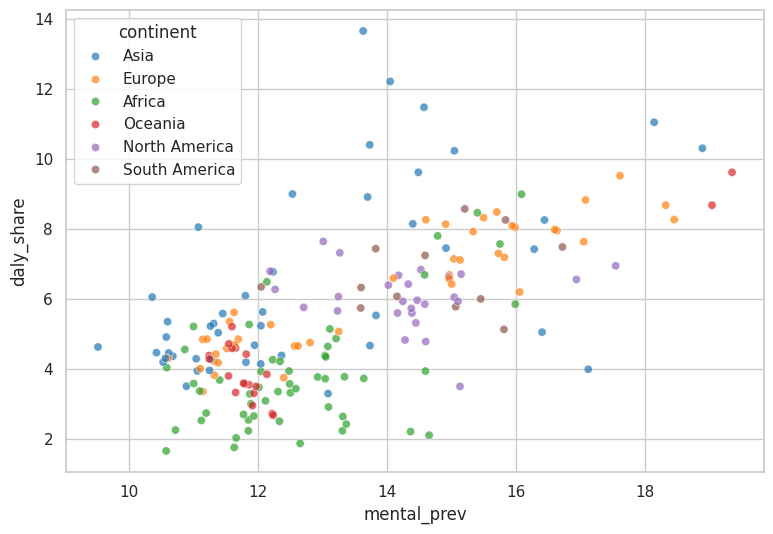

In [109]:
# Draw the base scatter plot colored by continent.
plt.figure(figsize=(9, 6))
sns.scatterplot(data=scatter_df, x='mental_prev', y='daly_share', hue='continent', alpha=0.7, palette='tab10')


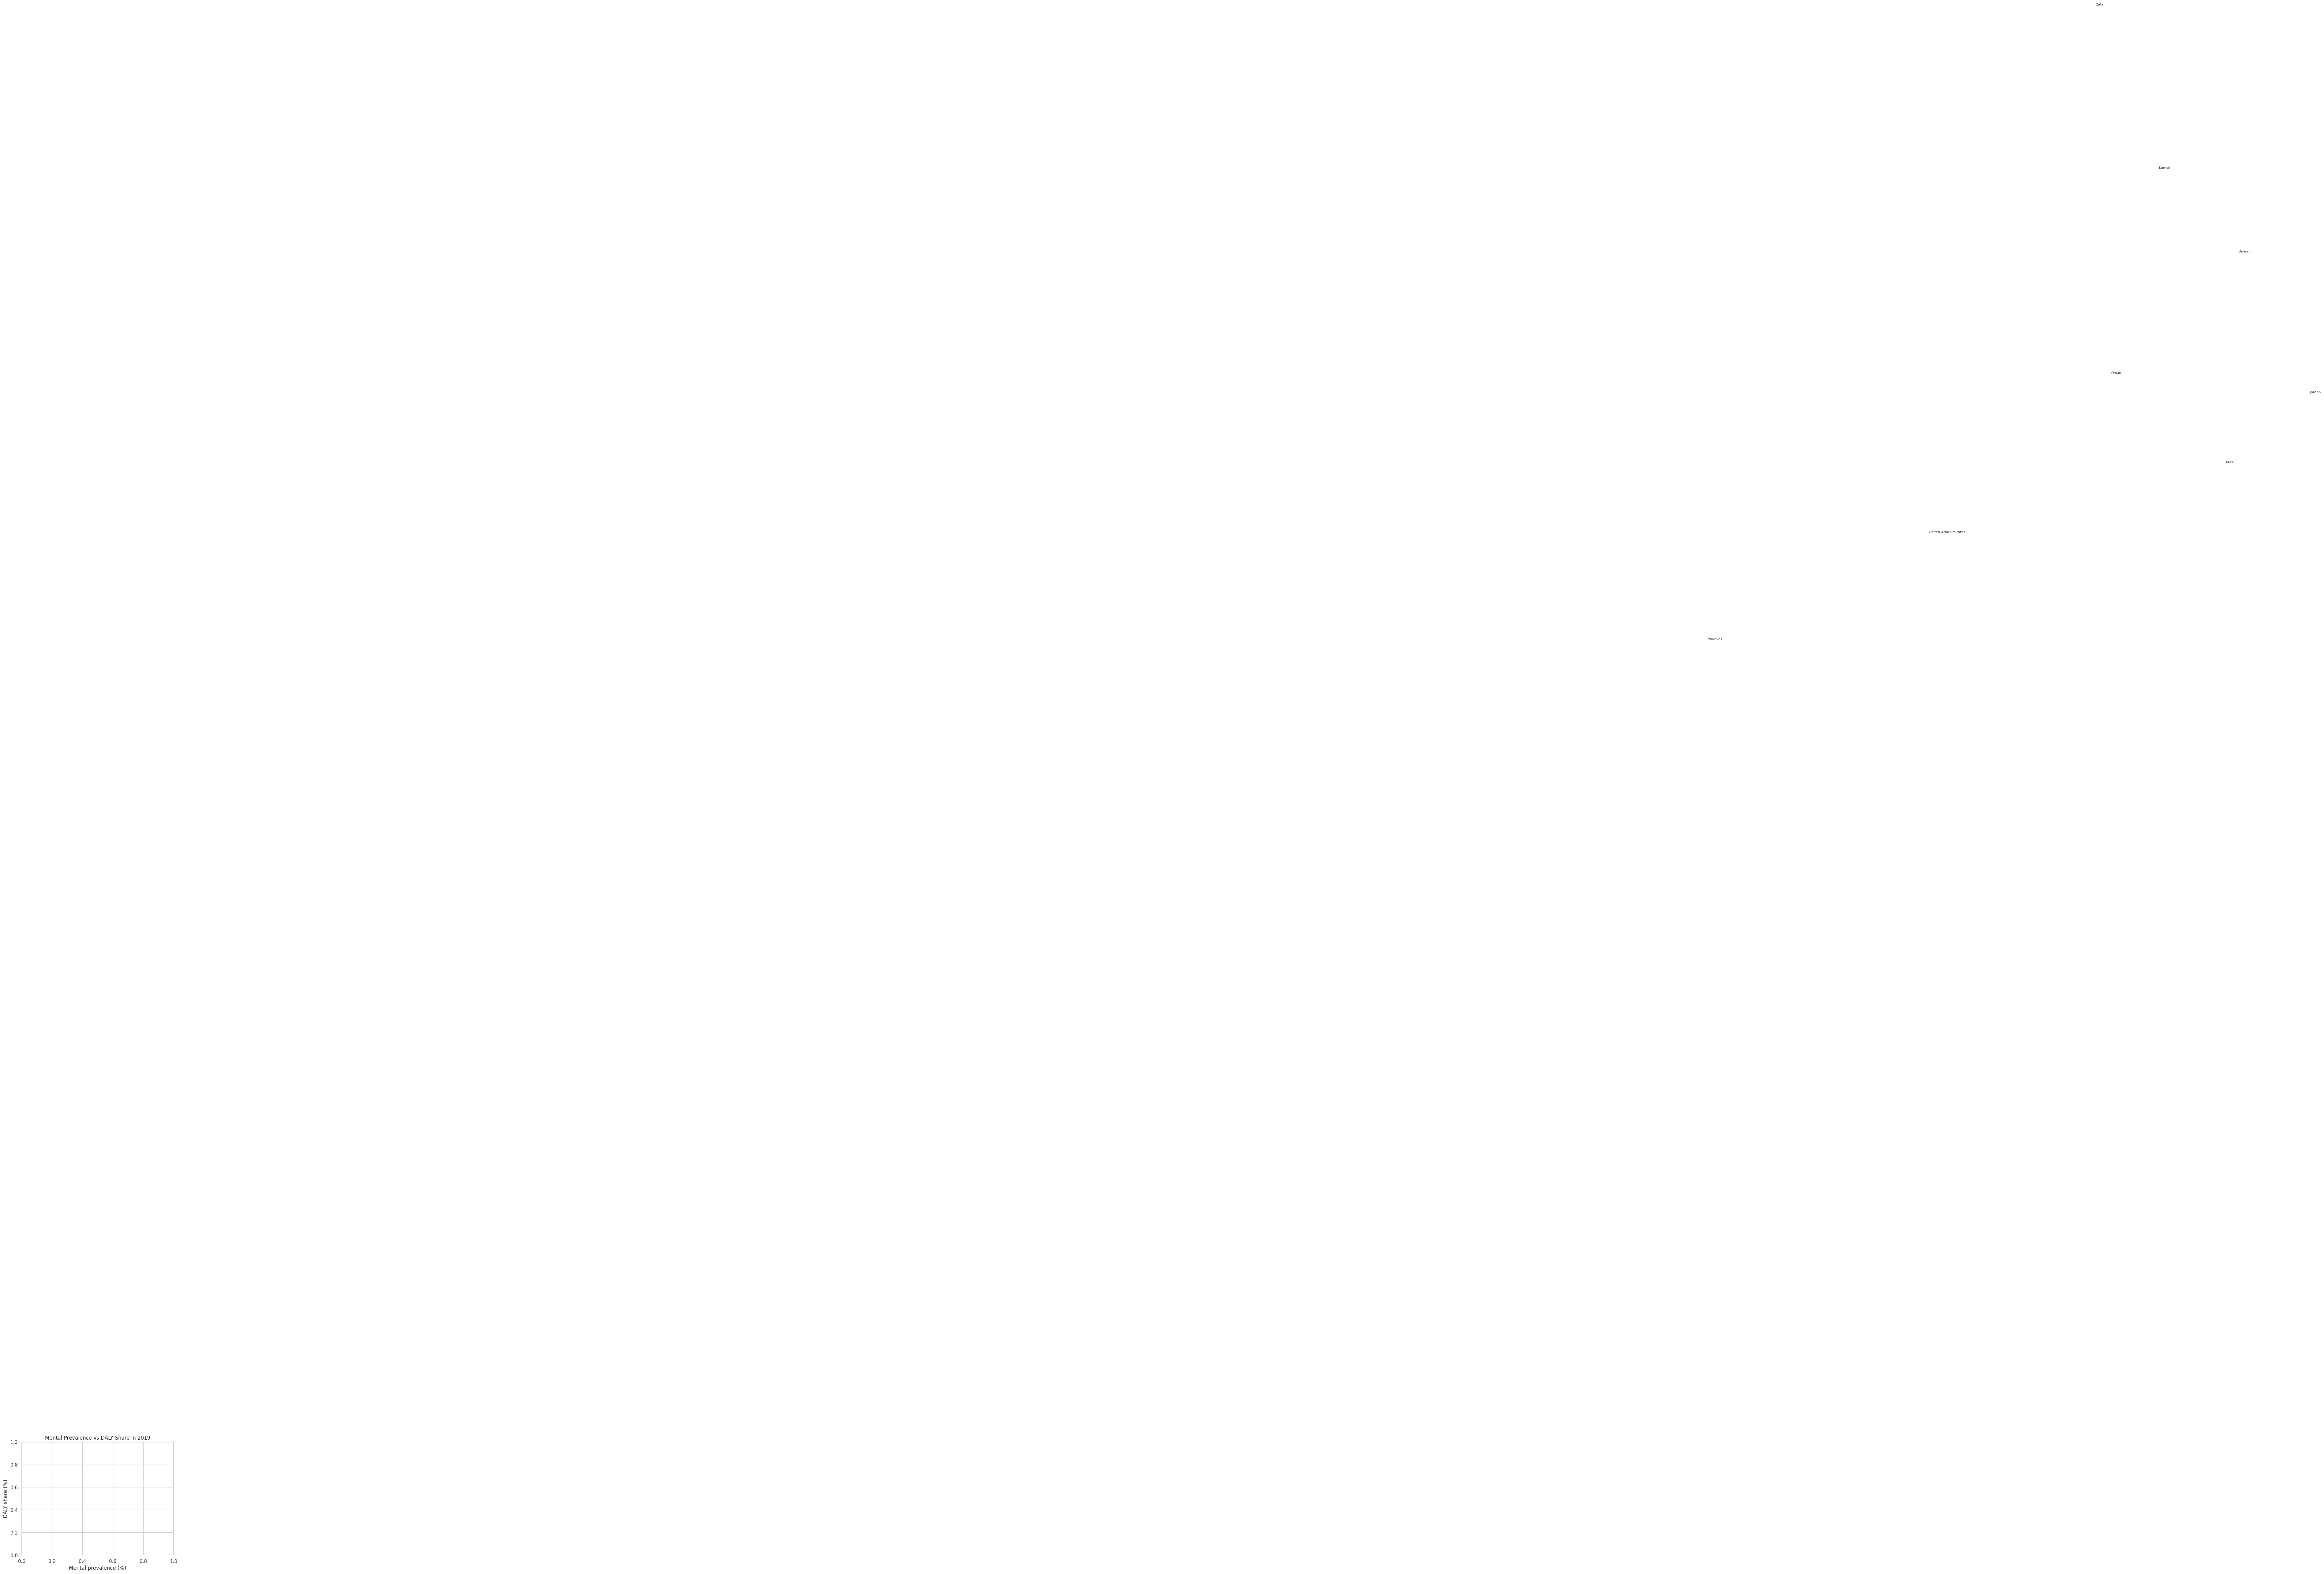

In [110]:
# Label the highest-burden countries and render the scatter chart.
for _, row in burden_2019.head(8).iterrows():
    plt.text(row['mental_prev'] + 0.03, row['daly_share'] + 0.03, row['Entity'], fontsize=8)
plt.title('Mental Prevalence vs DALY Share in 2019')
plt.xlabel('Mental prevalence (%)')
plt.ylabel('DALY share (%)')
plt.tight_layout()
plt.show()


In [111]:
# List the metrics that define each country's recent mental-health profile.
recent_metrics = [
    'mental_prev', 'depression_prev', 'anxiety_prev', 'alcohol_prev', 'drug_prev',
    'eating_prev', 'schizophrenia_prev', 'bipolar_prev', 'daly_share', 'depression_gender_gap'
]


In [112]:
# Average each recent metric across the 2015 to 2019 window.
recent_agg = {metric: 'mean' for metric in recent_metrics}


In [113]:
# Aggregate each country into a recent mental-health profile.
recent_profile = mental_panel[mental_panel['Year'].between(2015, 2019)].groupby(
    ['Entity', 'Code', 'continent'],
    as_index=False,
).agg(recent_agg)


In [114]:
# Select and standardize the clustering features.
cluster_features = [
    'mental_prev', 'depression_prev', 'anxiety_prev', 'alcohol_prev', 'drug_prev',
    'eating_prev', 'schizophrenia_prev', 'bipolar_prev', 'daly_share', 'depression_gender_gap'
]
scaled_recent = StandardScaler().fit_transform(recent_profile[cluster_features])


In [115]:
# Evaluate silhouette scores for candidate cluster counts.
silhouette_rows = []
for k in range(2, 7):
    kmeans = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = kmeans.fit_predict(scaled_recent)
    # Silhouette favors clusters that are both tight and well separated.
    silhouette_rows.append({'k': k, 'silhouette_score': silhouette_score(scaled_recent, labels)})


In [116]:
# Pick the best cluster count from the silhouette table.
silhouette_df = pd.DataFrame(silhouette_rows)
best_k = int(silhouette_df.sort_values('silhouette_score', ascending=False).iloc[0]['k'])


In [117]:
# Fit the final KMeans model and assign each country to a cluster.
final_kmeans = KMeans(n_clusters=best_k, n_init=30, random_state=42)
recent_profile['cluster'] = final_kmeans.fit_predict(scaled_recent)


In [118]:
# Start the cluster summary with the overall country count and key burden metrics.
cluster_profile_agg = {
    'countries': ('Code', 'nunique'),
    'mental_prev': ('mental_prev', 'mean'),
    'depression_prev': ('depression_prev', 'mean'),
    'daly_share': ('daly_share', 'mean'),
}


In [119]:
# Add the gap and disorder-mix metrics used to interpret each cluster.
cluster_profile_agg.update({
    'depression_gender_gap': ('depression_gender_gap', 'mean'),
    'alcohol_prev': ('alcohol_prev', 'mean'),
    'drug_prev': ('drug_prev', 'mean'),
    'eating_prev': ('eating_prev', 'mean'),
})


In [120]:
# Summarize each cluster with average prevalence and burden metrics.
cluster_profile = recent_profile.groupby('cluster').agg(**cluster_profile_agg)
cluster_profile = cluster_profile.sort_values('mental_prev')


In [121]:
# Grab example countries from each cluster for interpretation.
cluster_examples = (
    recent_profile.sort_values(['cluster', 'mental_prev'], ascending=[True, False])
    .groupby('cluster')
    .head(5)[['cluster', 'Entity', 'continent', 'mental_prev', 'daly_share']]
)


In [122]:
# Display the cluster diagnostics and examples.
display(silhouette_df)
print('Best number of clusters:', best_k)
display(cluster_profile)
display(cluster_examples)


,k,silhouette_score
0,2,0.3171
1,3,0.2859
2,4,0.2925
3,5,0.2847
4,6,0.2858


Best number of clusters: 2


,countries,mental_prev,depression_prev,daly_share,depression_gender_gap,alcohol_prev,drug_prev,eating_prev
cluster,,,,,,,,
1,128,12.0936,3.8195,4.0820,1.3754,1.3950,0.5755,0.1352
0,74,15.3419,4.0619,7.6221,1.7042,1.7208,1.0006,0.3762


,cluster,Entity,continent,mental_prev,daly_share
83,0,Iran,Asia,19.1245,10.2185
9,0,Australia,Oceania,19.0742,9.7783
126,0,New Zealand,Oceania,19.0346,8.9257
168,0,Spain,Europe,18.6532,8.9338
145,0,Portugal,Europe,18.4072,8.3490
0,1,Afghanistan,Asia,17.1121,3.7007
199,1,Yemen,Asia,16.0923,4.7613
170,1,Sudan,Africa,15.9900,5.3688
77,1,Haiti,North America,15.1122,3.3125
188,1,Uganda,Africa,14.6297,3.5527


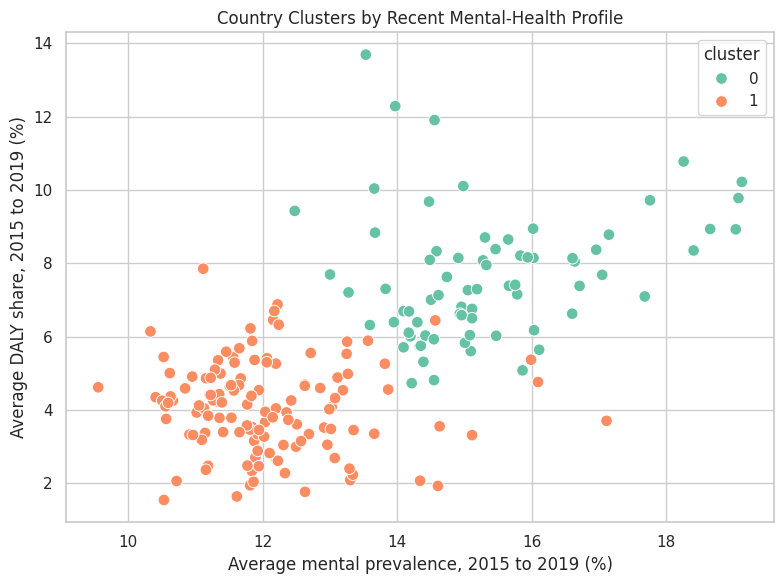

In [123]:
# Plot the recent country profiles colored by cluster.
plt.figure(figsize=(8, 6))
sns.scatterplot(data=recent_profile, x='mental_prev', y='daly_share', hue='cluster', palette='Set2', s=70)
plt.title('Country Clusters by Recent Mental-Health Profile')
plt.xlabel('Average mental prevalence, 2015 to 2019 (%)')
plt.ylabel('Average DALY share, 2015 to 2019 (%)')
plt.tight_layout()
plt.show()


## Conclusion

- Global mental-disorder prevalence is relatively stable in the aggregate, but country-level changes vary meaningfully.
- Female depression prevalence is consistently higher than male prevalence across the panel, with especially wide gaps in a subset of countries.
- Structural proxies alone explain part of the cross-country variation, but not all of it.
- In forecasting, simple persistence is very hard to beat because prevalence evolves slowly year to year.
- Recent country profiles separate cleanly into a lower-burden and higher-burden cluster structure.

## Next Improvements

- Enrich the project with external socioeconomic indicators such as GDP per capita, schooling, and unemployment.
- Extend forecasting to multi-year horizons or shock periods instead of only one-step-ahead prediction.
- Turn the notebook outputs into a dashboard for easier country comparison.
